# `gum.config` :the configuration object for pyAgrum

| | | |
|-|-|-|
|[ ![Creative Commons License](images/cc4.png)](http://creativecommons.org/licenses/by-nc/4.0/) |[ ![aGrUM](images/logoAgrum.png)](https://pyagrum.gitlab.io) |[ ![interactive online version](images/atbinder.svg)](https://mybinder.org/v2/gl/agrumery%2FaGrUM/forBinder?urlpath=%2Fdoc%2Ftree%2Fwrappers%2Fpyagrum%2Fdoc%2Fsphinx%2Fnotebooks%2F99-Tools_configForPyAgrum.ipynb)

In [1]:
import pyagrum as gum

print("=" * 35)
print(gum.config)
print("=" * 35)

[core]
  maxnumberofthreads = -1
  jgumindent = -1
  allowmodificationwhensaving = False
  epsiloncoarse = 1e-2
  epsilonstandard = 1e-6
  epsilonfine = 1e-10
[approximation]
  epsilon = 0.05
  minepsilonrate = 0.01
  maxiter = 10000
  maxtime = 1.0
  burnin = 0
  periodsize = 1
  verbosity = False
[sampling]
  maxiter = 10000000
  epsilon = 0.01
  maxtime = 6000.0
  periodsize = 100
  minepsilonrate = 1e-5
  verbosity = False
[gibbs]
  epsilon = 0.20189651799465538
  minepsilonrate = 0.006737946999085467
  burnin = 300
  percentdrawnsample = 50
  drawnatrandom = True
[lbp]
  maxiter = 100
  epsilon = 1e-8
  minepsilonrate = 1e-10
  periodsize = 1
  verbosity = False
[loopySampling]
  virtuallbpsize = 5000
[gibbsKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate = 1e-10
  periodsize = 200
  verbosity = False
  burnin = 2000
  maxtime = 6000.0
  percentdrawnsample = 10
  drawnatrandom = True
[mcKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate = 1e-10
  periodsize = 2

### `pyagrum.ini`

`gum.config` is the configuration singleton of the aGrUM C++ library (`gum::Configuration`), which holds all the logic (types, checks, hooks, loading and saving). The configuration is a mix between the defaults (those of aGrUM followed by those of pyAgrum, embedded in the library, which exactly define the possible `section` and `property`) and a file `pyagrum.ini` (if present in the current folder) that contains only the changed properties : this file never creates a section or a property. 

`section` and `key` are case insensitive.

Each property is declared in the defaults by a metadata line ``### type :: one-line documentation`` where the type is `int`, `float`, `bool`, `str`, an enumeration of the allowed values (`svg|png`) or a deprecation (`deprecated -> section.key`).

### `config` constantly keeps track of the differences between defaults and actual values :

In [2]:
gum.config["dynamicBN", "graphSize"] = 10

print("Configuration only for the current session")
print("-" * 40)
gum.config.diff()

Configuration only for the current session
----------------------------------------
[dynamicBN]
  graphsize = 10


In [3]:
# if there is a local modification, __repr__ shows only the diff other wise it show all properties
gum.config

[dynamicBN]
  graphsize = 10

In [4]:
# __str__ shows all the properties
print(gum.config)

[core]
  maxnumberofthreads = -1
  jgumindent = -1
  allowmodificationwhensaving = False
  epsiloncoarse = 1e-2
  epsilonstandard = 1e-6
  epsilonfine = 1e-10
[approximation]
  epsilon = 0.05
  minepsilonrate = 0.01
  maxiter = 10000
  maxtime = 1.0
  burnin = 0
  periodsize = 1
  verbosity = False
[sampling]
  maxiter = 10000000
  epsilon = 0.01
  maxtime = 6000.0
  periodsize = 100
  minepsilonrate = 1e-5
  verbosity = False
[gibbs]
  epsilon = 0.20189651799465538
  minepsilonrate = 0.006737946999085467
  burnin = 300
  percentdrawnsample = 50
  drawnatrandom = True
[lbp]
  maxiter = 100
  epsilon = 1e-8
  minepsilonrate = 1e-10
  periodsize = 1
  verbosity = False
[loopySampling]
  virtuallbpsize = 5000
[gibbsKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate = 1e-10
  periodsize = 200
  verbosity = False
  burnin = 2000
  maxtime = 6000.0
  percentdrawnsample = 10
  drawnatrandom = True
[mcKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate = 1e-10
  periodsize = 2

## Accessors

### Getter

In [5]:
print(gum.config["notebook", "evidence_bgcolor"])
print(gum.config.get("notebook", "evidence_bgcolor"))

sandybrown
sandybrown


### Setter

In [6]:
gum.config["notebook", "evidence_bgcolor"] = "papayawhip"
gum.config["causal", "graphSize"] = 1.9

In [7]:
gum.config  # once again, only the diff with defaults

[notebook]
  evidence_bgcolor = papayawhip
[dynamicBN]
  graphsize = 10
[causal]
  graphsize = 1.9

### constant structure, mutable content

The structure `section.key` is fixed by default and readonly : one can only change the value of an existing property

In [8]:
try:
  gum.config["AAA", "OOO"] = 1
except SyntaxError as e:
  print(f"Syntax error : {e.msg}")

Syntax error : Section 'AAA' unknown in configuration.


In [9]:
try:
  gum.config["causal", "OOO"] = 1
except SyntaxError as e:
  print(f"Syntax error : {e.msg}")

Syntax error : Key 'causal.OOO' unknown in configuration.


### Typed properties

Each property has a declared type: `int`, `float`, `bool`, `str` or an enumeration of the allowed values. The setter refuses a value that does not respect this type and canonicalizes the accepted values: a boolean can be written `True`/`False`, `0`/`1`, `off`/`on` or `no`/`yes` (case-insensitive) but is always stored as `True` or `False`, an enumerated value is stored with its declared casing.

In [10]:
try:
  gum.config["notebook", "tensor_visible_digits"] = "abc"
except ValueError as e:
  print(f"Value error : {e}")

Value error : [pyAgrum] Invalid argument: 'abc' must be an int for 'notebook.tensor_visible_digits'.


In [11]:
try:
  gum.config["notebook", "graph_format"] = "jpg"
except ValueError as e:
  print(f"Value error : {e}")

Value error : [pyAgrum] Invalid argument: 'jpg' must be one of svg|png for 'notebook.graph_format'.


In [12]:
# enumerated values are case-insensitive and canonicalized
gum.config["notebook", "graph_format"] = "PNG"
print(gum.config["notebook", "graph_format"])
gum.config["notebook", "graph_format"] = "svg"

png


In [13]:
# boolean values accept several spellings (case-insensitive) and are canonicalized to True/False
try:
  gum.config["notebook", "tensor_with_colors"] = "maybe"
except ValueError as e:
  print(f"Value error : {e}")

gum.config["notebook", "tensor_with_colors"] = "off"
print(gum.config["notebook", "tensor_with_colors"])
gum.config["notebook", "tensor_with_colors"] = "YES"
print(gum.config["notebook", "tensor_with_colors"])
gum.config["notebook", "tensor_with_colors"] = True

Value error : [pyAgrum] Invalid argument: 'maybe' must be a boolean (False/True, 0/1, Off/On, No/Yes) for 'notebook.tensor_with_colors'.
False
True


### Documentation of the properties

The declared type and a one-line documentation are available for every property with `gum.config.doc` :

In [14]:
print(gum.config.doc("notebook", "tensor_visible_digits"))
print(gum.config.doc("notebook", "graph_format"))
print(gum.config.doc("notebook", "tensor_parent_values"))

int[0,] :: number of visible digits when displaying a tensor in a notebook
svg|png :: format used to render graphs in a notebook
merge|revmerge|nomerge :: how to display the parent values in a tensor


### Deprecated properties

A property can be marked as deprecated in the defaults, with a replacement key (`### deprecated -> section.key :: message`). In that case :

- reading or writing the old key emits a `DeprecationWarning` and transparently uses the replacement key,
- the old key never appears in `diff()`, `save()` or `print(gum.config)`,
- if a `pyagrum.ini` still uses the old key, `gum.config.load()` accepts it (with a warning) and applies it to the new key, and `gum.config.save()` then writes `pyagrum.ini` with the new key : user files are migrated when saved.

For instance, the properties whose name started with `default_` in aGrUM 3.2.1 (such as `gum.config["notebook", "default_node_bgcolor"]`) have been renamed without this prefix, and the keys that are also used by the C++ graph drawing are now in lowerCamelCase (`gum.config["notebook", "nodeBgColor"]` instead of `node_bgcolor`) : the old names are deprecated properties and are still accepted.

### properties as string

All the properties are stored as string !

In [15]:
gum.config["notebook", "graphSize"]

'5'

In [16]:
gum.config["notebook", "graphSize"] = 10
gum.config["notebook", "graphSize"]

'10'

### ... but can be typed using `typed`

Since every property has a declared type, `gum.config.typed` returns the value converted to this type (enumerations stay strings). The historical accessors `asInt`, `asFloat`, `asBool` are deprecated since 3.1.0: they emit a `DeprecationWarning` and delegate to `typed`.

In [17]:
gum.config["dynamicBN", "graphSize"]

'10'

In [18]:
gum.config.typed["dynamicBN", "graphSize"]

'10'

In [19]:
print(type(gum.config["dynamicBN", "graphSize"]))
print(type(gum.config.typed["dynamicBN", "graphSize"]))

<class 'str'>
<class 'str'>


In [20]:
if gum.config["causal", "showLatentNames"] == "False":
  print("not very convenient test")
if not gum.config.typed["causal", "showLatentNames"]:
  print("better test")

not very convenient test
better test


### Reset, reload, save

The configuration can be saved in the current folder (`gum.config.save()`).

The configuration can be restored from the default (reset) or the current saved state (reload).

In [21]:
gum.config.reset()  # back to defaults
gum.config  # no diff => shows all the properties

# no customized property
[core]
  maxnumberofthreads = -1
  jgumindent = -1
  allowmodificationwhensaving = False
  epsiloncoarse = 1e-2
  epsilonstandard = 1e-6
  epsilonfine = 1e-10
[approximation]
  epsilon = 0.05
  minepsilonrate = 0.01
  maxiter = 10000
  maxtime = 1.0
  burnin = 0
  periodsize = 1
  verbosity = False
[sampling]
  maxiter = 10000000
  epsilon = 0.01
  maxtime = 6000.0
  periodsize = 100
  minepsilonrate = 1e-5
  verbosity = False
[gibbs]
  epsilon = 0.20189651799465538
  minepsilonrate = 0.006737946999085467
  burnin = 300
  percentdrawnsample = 50
  drawnatrandom = True
[lbp]
  maxiter = 100
  epsilon = 1e-8
  minepsilonrate = 1e-10
  periodsize = 1
  verbosity = False
[loopySampling]
  virtuallbpsize = 5000
[gibbsKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate = 1e-10
  periodsize = 200
  verbosity = False
  burnin = 2000
  maxtime = 6000.0
  percentdrawnsample = 10
  drawnatrandom = True
[mcKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate

In [22]:
try:
  gum.config.load()  # reload pyagrum.ini
except FileNotFoundError:
  pass  # no pyagrum.ini in the folder
gum.config

# no customized property
[core]
  maxnumberofthreads = -1
  jgumindent = -1
  allowmodificationwhensaving = False
  epsiloncoarse = 1e-2
  epsilonstandard = 1e-6
  epsilonfine = 1e-10
[approximation]
  epsilon = 0.05
  minepsilonrate = 0.01
  maxiter = 10000
  maxtime = 1.0
  burnin = 0
  periodsize = 1
  verbosity = False
[sampling]
  maxiter = 10000000
  epsilon = 0.01
  maxtime = 6000.0
  periodsize = 100
  minepsilonrate = 1e-5
  verbosity = False
[gibbs]
  epsilon = 0.20189651799465538
  minepsilonrate = 0.006737946999085467
  burnin = 300
  percentdrawnsample = 50
  drawnatrandom = True
[lbp]
  maxiter = 100
  epsilon = 1e-8
  minepsilonrate = 1e-10
  periodsize = 1
  verbosity = False
[loopySampling]
  virtuallbpsize = 5000
[gibbsKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate = 1e-10
  periodsize = 200
  verbosity = False
  burnin = 2000
  maxtime = 6000.0
  percentdrawnsample = 10
  drawnatrandom = True
[mcKL]
  maxiter = 10000000
  epsilon = 1e-10
  minepsilonrate

The current state can also be stacked (`push`) and restored later (`pop`) : handy to change a property for a short time. `pop` on an empty stack raises an `IndexError`.

If `pyagrum.ini` contains a malformed line, `gum.config.load()` raises a `SyntaxError` and nothing is changed (the file is read completely before any property is modified).

In [23]:
gum.config.push()
gum.config["notebook", "graphSize"] = 3
print("inside :", gum.config["notebook", "graphSize"])
gum.config.pop()
print("after pop :", gum.config["notebook", "graphSize"])

inside : 3
after pop : 5


## Using configuration

In [24]:
import pyagrum.lib.notebook as gnb

bn = gum.fastBN("D->C<-A->B[4];A->E")
bn.cpt("B")

(pyagrum.Tensor@0x779f0c13c0) 
      ║  B                                    │
A     ║0        │1        │2        │3        │
──────║─────────│─────────│─────────│─────────│
0     ║ 0.2608  │ 0.0567  │ 0.4782  │ 0.2043  │
1     ║ 0.0022  │ 0.3822  │ 0.4309  │ 0.1847  │

In [25]:
gum.config["notebook", "tensor_visible_digits"] = 1
bn.cpt("B")

(pyagrum.Tensor@0x779f0c13c0) 
      ║  B                                    │
A     ║0        │1        │2        │3        │
──────║─────────│─────────│─────────│─────────│
0     ║ 0.2608  │ 0.0567  │ 0.4782  │ 0.2043  │
1     ║ 0.0022  │ 0.3822  │ 0.4309  │ 0.1847  │

In [26]:
gum.config["notebook", "tensor_color_0"] = "#AA00AA"
gum.config["notebook", "tensor_color_1"] = "#00FFAA"
bn.cpt("B")

(pyagrum.Tensor@0x779f0c13c0) 
      ║  B                                    │
A     ║0        │1        │2        │3        │
──────║─────────│─────────│─────────│─────────│
0     ║ 0.2608  │ 0.0567  │ 0.4782  │ 0.2043  │
1     ║ 0.0022  │ 0.3822  │ 0.4309  │ 0.1847  │

In [27]:
gum.config["notebook", "tensor_visible_digits"] = 4
gnb.flow.add(bn.cpt("B"), "Ugly float")

gum.config["notebook", "tensor_visible_digits"] = 1
gnb.flow.add(bn.cpt("B"), "Ugly 1digit-float")

gum.config["notebook", "tensor_with_fraction"] = True
gum.config["notebook", "tensor_fraction_with_latex"] = False
gum.config["notebook", "tensor_fraction_limit"] = 2000
gnb.flow.add(bn.cpt("B"), "Simple fraction")

gum.config["notebook", "tensor_fraction_with_latex"] = True
gnb.flow.add(bn.cpt("B"), "Sophisticated fraction with LaTeX")
gnb.flow.display()

In [28]:
gnb.sideBySide(bn, gnb.getInference(bn, evs={"A": 1}, targets={"B"}))

anonymousBN <!-- D --> D D <!-- C --> C C <!-- D->C --> D->C <!-- A --> A A <!-- A->C --> A->C <!-- B --> B B <!-- A->B --> A->B <!-- E --> E E <!-- A->E --> A->E


In [29]:
gum.config["notebook", "evidence_bgcolor"] = "green"
gum.config["notebook", "nodeBgColor"] = "yellow"
gum.config["notebook", "nodeFgColor"] = "red"
gnb.sideBySide(bn, gnb.getInference(bn, evs={"A": 1}, targets={"B"}))

anonymousBN <!-- D --> D D <!-- C --> C C <!-- D->C --> D->C <!-- A --> A A <!-- A->C --> A->C <!-- B --> B B <!-- A->B --> A->B <!-- E --> E E <!-- A->E --> A->E


In [30]:
gum.config["notebook", "graphSize"] = 1
gnb.sideBySide(bn, gnb.getInference(bn, evs={"A": 1}, targets={"B"}))

anonymousBN <!-- D --> D D <!-- C --> C C <!-- D->C --> D->C <!-- A --> A A <!-- A->C --> A->C <!-- B --> B B <!-- A->B --> A->B <!-- E --> E E <!-- A->E --> A->E


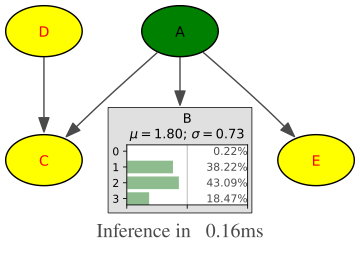

In [31]:
gum.config["notebook", "graph_inference_size"] = "5!"
gnb.showInference(bn, evs={"A": 1}, targets={"B"})

## Finding a specific property

In [32]:
# find anything containing arc
gum.config.grep("arc")

[notebook]
  arccolor = #4A4A4A
  arc_cmap = BuGn
[influenceDiagram]
  decisionarcstyle = tapered, bold, dotted
  utilityarcstyle = dashed
[bnmixture]
  arc_cmap = Greens
  arc_color = #4A4A4A
  arc_style = solid
  correct_arc_style = solid
  correct_arc_color = green
  incorrect_arc_style = dashed
  incorrect_arc_color = green


In [33]:
# find anything containing default
gum.config.grep("default")

In [34]:
# if a section contains the search, all its properties are shown
gum.config.grep("caus")

[causal]
  showlatentnames = False
  graphsize = 2.5
  nodebgcolor = #404040
  nodefgcolor = adaptive
  latentbgcolor = #A08080
  latentfgcolor = adaptive
  latex_do_prefix = \text{do}(
  latex_do_suffix = )


## Saving current configuration in `pyagrum.ini`

In [35]:
gum.config.reset()  # back to defaults
gum.config["notebook", "arcColor"] = "#AAAAAA"
gum.config["notebook", "evidence_bgcolor"] = "green"
gum.config.save()  # store curent changes

In [36]:
gum.config.reset()  # back to defaults
gum.config.save()  # store defaults back

### From gum.config to ConfigParser

In [37]:
from configparser import ConfigParser

c = ConfigParser()

gum.config["notebook", "arcColor"] = "#AAAAAA"
gum.config["notebook", "evidence_bgcolor"] = "green"
c.read_string(gum.config.__repr__())
print(c.sections())

['notebook']


### Hooks

A function without argument can be registered with `gum.config.add_hook`. It is called after each change of the configuration (`set`, `reset`, `pop` and `load`), after the hooks of the aGrUM library itself (for instance the one which applies the number of threads). The hooks are stored by the C++ configuration: they are also called when the configuration is changed from C++.

A hook cannot be removed : it is kept until the end of the session. An exception raised by a hook is propagated to the code which changed the configuration.

In [38]:
def on_change():
  print("the configuration has changed")


gum.config.add_hook(on_change)

gum.config["notebook", "arcColor"] = "#BBBBBB"  # the hook is called

the configuration has changed


A single change can skip the hooks (`no_hook=True`), and the hooks can be run by hand :

In [39]:
gum.config.set("notebook", "arcColor", "#CCCCCC", no_hook=True)  # nothing is printed
gum.config.run_hooks()

the configuration has changed
